In [11]:
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, LabelEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [14]:
df = pd.read_csv('Hospital_Inpatient_Discharges__SPARCS_De-Identified___2021_20231012 2.csv', na_values=['120 +'])

df.head()

/var/folders/t0/tpz18mtn6dx0mqhzlp2q92tr0000gn/T/ipykernel_3662/3530454461.py:1: DtypeWarning: Columns (0: Birth Weight) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('Hospital_Inpatient_Discharges__SPARCS_De-Identified___2021_20231012 2.csv', na_values=['120 +'])


,Hospital Service Area,Hospital County,Operating Certificate Number,Permanent Facility Id,Facility Name,Age Group,Zip Code - 3 digits,Gender,Race,Ethnicity,...,APR Severity of Illness Description,APR Risk of Mortality,APR Medical Surgical Description,Payment Typology 1,Payment Typology 2,Payment Typology 3,Birth Weight,Emergency Department Indicator,Total Charges,Total Costs
0,New York City,Bronx,7000006.0,1169.0,Montefiore Medical Center - Henry & Lucy Moses...,70 or Older,104,M,Other Race,Spanish/Hispanic,...,Major,Extreme,Medical,Medicare,Medicaid,NaN,NaN,Y,"320,922.43","60,241.34"
1,New York City,Bronx,7000006.0,1169.0,Montefiore Medical Center - Henry & Lucy Moses...,50 to 69,104,F,White,Not Span/Hispanic,...,Moderate,Minor,Medical,Private Health Insurance,NaN,NaN,NaN,Y,"61,665.22","9,180.69"
2,New York City,Bronx,7000006.0,1168.0,Montefiore Medical Center-Wakefield Hospital,18 to 29,104,F,Other Race,Spanish/Hispanic,...,Minor,Minor,Surgical,Medicaid,NaN,NaN,NaN,N,"42,705.34","11,366.5"
3,New York City,Bronx,7000006.0,3058.0,Montefiore Med Center - Jack D Weiler Hosp of ...,70 or Older,104,M,Other Race,Spanish/Hispanic,...,Major,Major,Medical,Medicare,Medicaid,NaN,NaN,Y,"72,700.17","12,111.75"
4,New York City,Bronx,7000006.0,1169.0,Montefiore Medical Center - Henry & Lucy Moses...,50 to 69,104,F,Black/African American,Not Span/Hispanic,...,Moderate,Minor,Medical,Medicare,Medicaid,NaN,NaN,Y,"55,562.51","8,339.72"


In [15]:
df = df.drop_duplicates().fillna(df.median(numeric_only=True))

df.head()

,Hospital Service Area,Hospital County,Operating Certificate Number,Permanent Facility Id,Facility Name,Age Group,Zip Code - 3 digits,Gender,Race,Ethnicity,...,APR Severity of Illness Description,APR Risk of Mortality,APR Medical Surgical Description,Payment Typology 1,Payment Typology 2,Payment Typology 3,Birth Weight,Emergency Department Indicator,Total Charges,Total Costs
0,New York City,Bronx,7000006.0,1169.0,Montefiore Medical Center - Henry & Lucy Moses...,70 or Older,104,M,Other Race,Spanish/Hispanic,...,Major,Extreme,Medical,Medicare,Medicaid,NaN,NaN,Y,"320,922.43","60,241.34"
1,New York City,Bronx,7000006.0,1169.0,Montefiore Medical Center - Henry & Lucy Moses...,50 to 69,104,F,White,Not Span/Hispanic,...,Moderate,Minor,Medical,Private Health Insurance,NaN,NaN,NaN,Y,"61,665.22","9,180.69"
2,New York City,Bronx,7000006.0,1168.0,Montefiore Medical Center-Wakefield Hospital,18 to 29,104,F,Other Race,Spanish/Hispanic,...,Minor,Minor,Surgical,Medicaid,NaN,NaN,NaN,N,"42,705.34","11,366.5"
3,New York City,Bronx,7000006.0,3058.0,Montefiore Med Center - Jack D Weiler Hosp of ...,70 or Older,104,M,Other Race,Spanish/Hispanic,...,Major,Major,Medical,Medicare,Medicaid,NaN,NaN,Y,"72,700.17","12,111.75"
4,New York City,Bronx,7000006.0,1169.0,Montefiore Medical Center - Henry & Lucy Moses...,50 to 69,104,F,Black/African American,Not Span/Hispanic,...,Moderate,Minor,Medical,Medicare,Medicaid,NaN,NaN,Y,"55,562.51","8,339.72"


In [16]:
# Filter 1.5*IQR outliers on numerical features -> df_model (n = 2,306)

In [37]:
df['Length of Stay'] = pd.to_numeric(
    df['Length of Stay'], errors='coerce'
).astype(float)

df['Total Charges'] = pd.to_numeric(
    df['Total Charges'].astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False),
    errors='coerce'
).astype(float)

df = df.fillna(df.median(numeric_only=True))

df_model = df.copy()

Q1 = df[['Length of Stay', 'Total Charges']].quantile(0.25)
Q3 = df[['Length of Stay', 'Total Charges']].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_model = df_model[
    ~((df_model[['Length of Stay', 'Total Charges']] < lower) |
      (df_model[['Length of Stay', 'Total Charges']] > upper)).any(axis=1)
]

print(df_model.shape)

(2155, 33)


In [38]:
df = df.sample(n=2500, random_state=42)

In [39]:
df_model['Age_Encoded'] = LabelEncoder().fit_transform(df_model['Age Group'])

In [40]:
df_model = pd.get_dummies(
    df_model,
    columns=['Type of Admission'],
    drop_first=True,
    dtype=int
)

In [41]:
feature_cols = [
    'Length of Stay',
    'APR Severity of Illness Code',
    'APR DRG Code',
    'APR MDC Code',
    'Age_Encoded',
    'Type of Admission_Emergency',
    'Type of Admission_Newborn',
    'Type of Admission_Urgent'
]

In [42]:
X_tr, X_te, y_tr, y_te = train_test_split(
    df_model[feature_cols],
    df_model['Total Charges'],
    test_size=0.2,
    random_state=42
)

print("Training size:", len(X_tr))
print("Testing size:", len(X_te))

Training size: 1724
Testing size: 431


In [43]:
sc = StandardScaler()

X_tr_sc = sc.fit_transform(X_tr)
X_te_sc = sc.transform(X_te)

In [44]:
mlr = LinearRegression().fit(X_tr, y_tr)

In [45]:
poly2 = PolynomialFeatures(degree=2, include_bias=False)

poly_m = LinearRegression().fit(
    poly2.fit_transform(X_tr_sc), y_tr
)

In [46]:
ridge_m = Ridge(alpha=1.0).fit(X_tr_sc, y_tr)

In [47]:
lasso_m = Lasso(alpha=10.0).fit(X_tr_sc, y_tr)

In [48]:
enet_m = ElasticNet(alpha=0.1, l1_ratio=0.5).fit(X_tr_sc, y_tr)

In [49]:
gbr_m = GradientBoostingRegressor(
    n_estimators=120,
    max_depth=4,
    random_state=42
).fit(X_tr, y_tr)

In [50]:
y_pred_mlr = mlr.predict(X_te)

y_pred_poly = poly_m.predict(poly2.transform(X_te_sc))

y_pred_ridge = ridge_m.predict(X_te_sc)

y_pred_lasso = lasso_m.predict(X_te_sc)

y_pred_enet = enet_m.predict(X_te_sc)

y_pred_gbr = gbr_m.predict(X_te)

In [51]:
results = {
    'Multiple Linear Regression': y_pred_mlr,
    'Polynomial Regression': y_pred_poly,
    'Ridge Regression': y_pred_ridge,
    'Lasso Regression': y_pred_lasso,
    'Elastic Net Regression': y_pred_enet,
    'Gradient Boosting': y_pred_gbr
}

for name, prediction in results.items():
    print(name)
    print("MSE =", mean_squared_error(y_te, prediction))
    print("R2 =", r2_score(y_te, prediction))
    print()

Multiple Linear Regression
MSE = 867690005.4735618
R2 = 0.24307152734868398

Polynomial Regression
MSE = 813054921.848773
R2 = 0.2907323856510887

Ridge Regression
MSE = 866076945.5294515
R2 = 0.24447867851106708

Lasso Regression
MSE = 865415099.3818091
R2 = 0.24505603930870778

Elastic Net Regression
MSE = 849781562.6979734
R2 = 0.25869393875388547

Gradient Boosting
MSE = 738978851.0455573
R2 = 0.3553525688724999



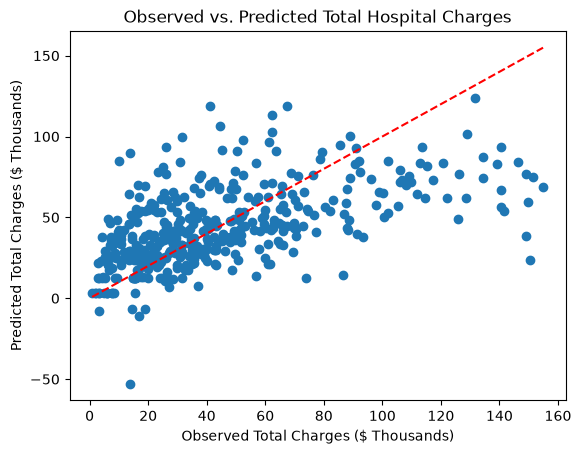

In [52]:
import matplotlib.pyplot as plt

plt.scatter(y_te / 1000, y_pred_poly / 1000)

plt.plot(
    [y_te.min() / 1000, y_te.max() / 1000],
    [y_te.min() / 1000, y_te.max() / 1000],
    'r--'
)

plt.title('Observed vs. Predicted Total Hospital Charges')
plt.xlabel('Observed Total Charges ($ Thousands)')
plt.ylabel('Predicted Total Charges ($ Thousands)')
plt.show()

In [53]:
print("Intercept =", mlr.intercept_)

coefficients = pd.DataFrame({
    'Variable': feature_cols,
    'Coefficient': mlr.coef_
})

print(coefficients)

Intercept = 31664.74948431157
                       Variable   Coefficient
0                Length of Stay   6954.848233
1  APR Severity of Illness Code   2872.518050
2                  APR DRG Code    -64.982725
3                  APR MDC Code   1589.873834
4                   Age_Encoded   3096.811967
5   Type of Admission_Emergency -19431.005234
6     Type of Admission_Newborn -17433.169666
7      Type of Admission_Urgent -21644.817069


In [54]:
records = df_model.iloc[[10, 45, 112, 230, 385]]

predicted = mlr.predict(records[feature_cols])

comparison = pd.DataFrame({
    'Observed': records['Total Charges'].values,
    'Predicted': predicted
})

print(comparison)

   Observed     Predicted
0   5143.75  40508.495383
1  31408.60  75889.046086
2  62714.00  63776.411525
3  22886.30  64104.275176
4  20049.25  19364.082824


In [55]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

In [56]:
df_model['Cost_Category'] = np.where(
    df_model['Total Charges'] >= 54400.0, 1, 0
)

print(df_model['Cost_Category'].value_counts())

Cost_Category
0    1546
1     609
Name: count, dtype: int64


In [57]:
X_tr_c, X_te_c, y_tr_c, y_te_c = train_test_split(
    df_model[feature_cols],
    df_model['Cost_Category'],
    test_size=0.2,
    random_state=42,
    stratify=df_model['Cost_Category']
)

In [58]:
sc_c = StandardScaler()

X_tr_c_sc = sc_c.fit_transform(X_tr_c)
X_te_c_sc = sc_c.transform(X_te_c)

In [59]:
clfs = {
    'Logistic Regression': LogisticRegression(random_state=42),

    'K-Nearest Neighbors (KNN)': KNeighborsClassifier(n_neighbors=7),

    'Support Vector Machine (SVM)': SVC(
        kernel='rbf', C=2.0, random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        max_depth=6, random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=120, max_depth=8, random_state=42
    ),

    'Gradient Boosting (Bonus)': GradientBoostingClassifier(
        n_estimators=100, max_depth=3, random_state=42
    )
}

In [60]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

for name, model in clfs.items():

    model.fit(X_tr_c_sc, y_tr_c)
    y_pred = model.predict(X_te_c_sc)

    print(name)
    print("Confusion Matrix:")
    print(confusion_matrix(y_te_c, y_pred))
    print("Errors =", sum(y_te_c != y_pred))
    print("Accuracy =", accuracy_score(y_te_c, y_pred))
    print("Precision =", precision_score(y_te_c, y_pred))
    print("Recall =", recall_score(y_te_c, y_pred))
    print("F1-Score =", f1_score(y_te_c, y_pred))
    print()

Logistic Regression
Confusion Matrix:
[[282  27]
 [ 72  50]]
Errors = 99
Accuracy = 0.7703016241299304
Precision = 0.6493506493506493
Recall = 0.4098360655737705
F1-Score = 0.5025125628140703

K-Nearest Neighbors (KNN)
Confusion Matrix:
[[281  28]
 [ 65  57]]
Errors = 93
Accuracy = 0.7842227378190255
Precision = 0.6705882352941176
Recall = 0.4672131147540984
F1-Score = 0.5507246376811594

Support Vector Machine (SVM)
Confusion Matrix:
[[287  22]
 [ 74  48]]
Errors = 96
Accuracy = 0.777262180974478
Precision = 0.6857142857142857
Recall = 0.39344262295081966
F1-Score = 0.5

Decision Tree
Confusion Matrix:
[[261  48]
 [ 58  64]]
Errors = 106
Accuracy = 0.7540603248259861
Precision = 0.5714285714285714
Recall = 0.5245901639344263
F1-Score = 0.5470085470085471

Random Forest
Confusion Matrix:
[[280  29]
 [ 67  55]]
Errors = 96
Accuracy = 0.777262180974478
Precision = 0.6547619047619048
Recall = 0.45081967213114754
F1-Score = 0.5339805825242718

Gradient Boosting (Bonus)
Confusion Matrix:
[[

In [61]:
best_model = clfs['Gradient Boosting (Bonus)']

predictions = best_model.predict(
    sc_c.transform(df_model[feature_cols])
)

print(pd.Series(predictions).value_counts())

0    1655
1     500
Name: count, dtype: int64


In [62]:
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

In [63]:
X_cluster = df_model[['Length of Stay', 'Total Charges']]

scaler = StandardScaler()

X_cluster_sc = scaler.fit_transform(X_cluster)

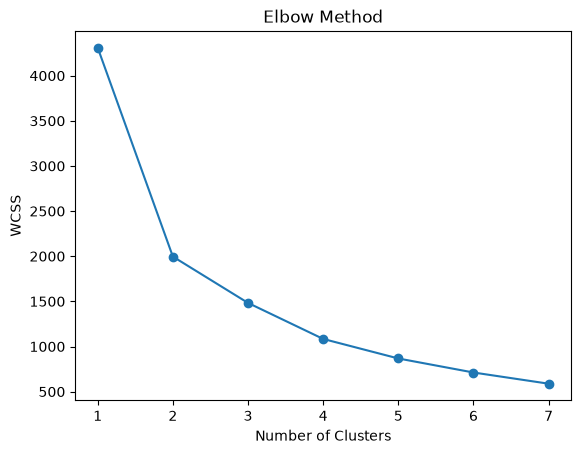

In [64]:
wcss = []

for i in range(1, 8):

    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)

    kmeans.fit(X_cluster_sc)

    wcss.append(kmeans.inertia_)

plt.plot(range(1, 8), wcss, marker='o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.show()

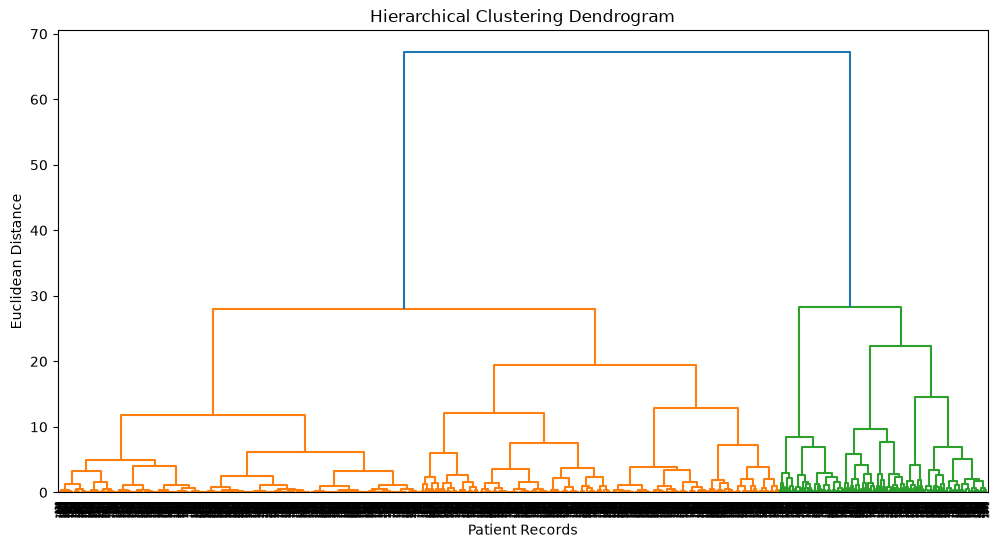

In [65]:
linked = linkage(X_cluster_sc, method='ward')

plt.figure(figsize=(12, 6))

dendrogram(linked)

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Patient Records')
plt.ylabel('Euclidean Distance')
plt.show()

In [66]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df_model['Cluster'] = kmeans.fit_predict(X_cluster_sc)

In [67]:
score = silhouette_score(
    X_cluster_sc,
    df_model['Cluster']
)

print("K-Means Silhouette Score =", score)

K-Means Silhouette Score = 0.4554246771229758


In [68]:
hc = AgglomerativeClustering(n_clusters=3, linkage='ward')

hc_labels = hc.fit_predict(X_cluster_sc)

print("Hierarchical Silhouette Score =",
      silhouette_score(X_cluster_sc, hc_labels))

Hierarchical Silhouette Score = 0.5154183194947575


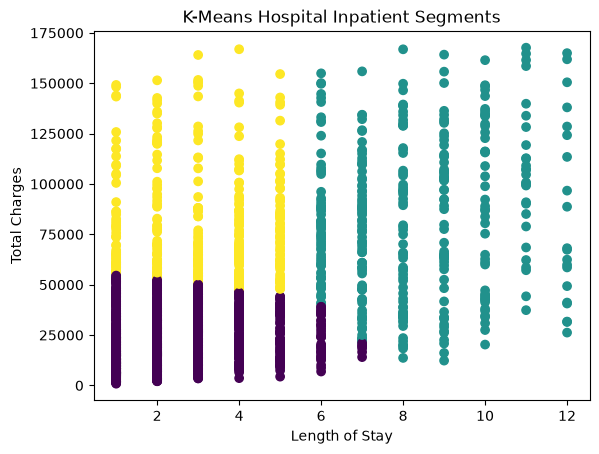

In [69]:
plt.scatter(
    df_model['Length of Stay'],
    df_model['Total Charges'],
    c=df_model['Cluster'],
    cmap='viridis'
)

plt.title('K-Means Hospital Inpatient Segments')
plt.xlabel('Length of Stay')
plt.ylabel('Total Charges')
plt.show()

In [70]:
print(df_model['Cluster'].value_counts())

Cluster
0    1393
2     389
1     373
Name: count, dtype: int64


In [71]:
df_model.groupby('Cluster')[
    ['Length of Stay',
     'Total Charges',
     'APR Severity of Illness Code']
].mean()

,Length of Stay,Total Charges,APR Severity of Illness Code
Cluster,,,
0,2.379756,22953.857128,1.773151
1,8.233244,81724.309571,2.611260
2,3.192802,78633.053008,2.066838
